# Clasificación de resonancias magnéticas cerebrales
### Implementación y evaluación de modelos de deep learning

**Autor:** Carlos Manuel Delgado Vázquez  
**Framework:** TensorFlow y Keras  
**Tipo de problema:** Clasificación multiclase de imágenes

---

## 1. Introducción

### Contexto

La clasificación de imágenes médicas permite estudiar cómo las redes
neuronales identifican patrones visuales asociados con diferentes
categorías. En este proyecto se explorará esta aplicación mediante
imágenes de resonancia magnética cerebral.

### Objetivo

**Desarrollar y evaluar un modelo que clasifique imágenes en cuatro
categorías**, utilizando las etiquetas del dataset:

| Categoría | Etiqueta |
|:----------|:---------|
| Glioma | `glioma` |
| Meningioma | `meningioma` |
| Tumor hipofisario | `pituitary` |
| Sin tumor | `notumor` |

### Estrategia de trabajo

1. Explorar y preparar los datos.
2. Entrenar una red neuronal convolucional inicial.
3. Realizar ajustes y comparar su desempeño mediante validación.
4. Evaluar la versión final con el conjunto de prueba reservado.
5. Implementar una función para clasificar imágenes nuevas.

> **Alcance académico:** los resultados describen el desempeño sobre
> este dataset. No constituyen una validación para diagnóstico clínico.

## 2. Datos

Se utilizará Brain Tumor MRI Dataset, publicado por Masoud Nickparvar
en Kaggle. Se trabajará con la versión 2 para facilitar la reproducción
del proyecto.

El dataset reúne imágenes de las fuentes Figshare, SARTAJ y Br35H,
organizadas en cuatro categorías:

- Glioma.
- Meningioma.
- Tumor hipofisario.
- Sin tumor.

Fuente:
https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset

Antes del entrenamiento se comprobarán la estructura de carpetas,
la cantidad de imágenes, su distribución, dimensiones y calidad.

También se revisarán duplicados y la disponibilidad de identificadores
de pacientes para determinar qué separación de datos puede realizarse
y qué limitaciones deben documentarse.

### 2.1 Preparación del entorno

Se importan las herramientas necesarias para descargar, explorar
y procesar las imágenes, así como para construir y evaluar los modelos.

In [2]:
%pip install -q kagglehub

In [3]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import kagglehub

# Facilitar la reproducción de los experimentos
SEED = 42
keras.utils.set_random_seed(SEED)

# Configuración inicial
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

# Carpeta independiente del proyecto de tenis
OUTPUT_DIR = Path("resultados_brain")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Versión de TensorFlow:", tf.__version__)
print("GPU disponible:", tf.config.list_physical_devices("GPU"))
print("Carpeta de resultados:", OUTPUT_DIR)

Versión de TensorFlow: 2.21.0
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Carpeta de resultados: resultados_brain


### 2.2 Descarga e inspección de la estructura

Se descarga la versión 2 del dataset y se inspeccionan sus carpetas
antes de construir la tabla de imágenes.

Se revisará la separación original entre Training y Testing.
Todavía no se crearán nuevas particiones ni se entrenará el modelo.

In [4]:
DATA_PATH = Path(
    kagglehub.dataset_download(
        "masoudnickparvar/brain-tumor-mri-dataset/versions/2"
    )
)

print("Ubicación del dataset:", DATA_PATH)

# Mostrar hasta tres niveles de carpetas
print("\nEstructura de carpetas:")

for folder in sorted(DATA_PATH.rglob("*")):
    if folder.is_dir():
        relative_path = folder.relative_to(DATA_PATH)

        if len(relative_path.parts) <= 3:
            print(relative_path)

# Localizar las imágenes
extensions = {".jpg", ".jpeg", ".png", ".bmp"}

image_paths = sorted(
    path
    for path in DATA_PATH.rglob("*")
    if path.is_file() and path.suffix.lower() in extensions
)

assert image_paths, "No se encontraron imágenes."

print("\nTotal de imágenes encontradas:", len(image_paths))

print("\nEjemplos de nombres y rutas:")
for path in image_paths[:8]:
    print(path.relative_to(DATA_PATH))

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Ubicación del dataset: /kaggle/input/brain-tumor-mri-dataset

Estructura de carpetas:
Testing
Testing/glioma
Testing/meningioma
Testing/notumor
Testing/pituitary
Training
Training/glioma
Training/meningioma
Training/notumor
Training/pituitary

Total de imágenes encontradas: 7200

Ejemplos de nombres y rutas:
Testing/glioma/Te-gl_1.jpg
Testing/glioma/Te-gl_10.jpg
Testing/glioma/Te-gl_100.jpg
Testing/glioma/Te-gl_101.jpg
Testing/glioma/Te-gl_102.jpg
Testing/glioma/Te-gl_103.jpg
Testing/glioma/Te-gl_104.jpg
Testing/glioma/Te-gl_105.jpg


### 2.3 Exploración de las categorías

Se construye una tabla con la ruta, categoría y partición original
de cada imagen.

Se revisará la distribución de las cuatro categorías en Training
y Testing. La inspección visual se realizará únicamente con imágenes
de entrenamiento.

Los nombres de archivo mostrados contienen un prefijo y una numeración,
pero no permiten confirmar por sí solos la identidad del paciente.
No se asumirá que cada imagen corresponde a una persona diferente.

In [5]:
rows = []

for path in image_paths:
    relative_path = path.relative_to(DATA_PATH)

    rows.append({
        "path": str(path),
        "class_name": path.parent.name,
        "original_split": relative_path.parts[0]
    })

df = pd.DataFrame(rows)

# Comprobar que las carpetas sean las esperadas
expected_classes = {
    "glioma",
    "meningioma",
    "notumor",
    "pituitary"
}

assert set(df["class_name"]) == expected_classes
assert set(df["original_split"]) == {"Training", "Testing"}

print("Total de imágenes:", len(df))
print("Categorías:", df["class_name"].nunique())

display(df.head())

# Contar imágenes por categoría y partición
distribution = pd.crosstab(
    df["class_name"],
    df["original_split"]
).reindex(columns=["Training", "Testing"])

distribution["Total"] = distribution.sum(axis=1)

display(distribution)

print("\nTotales por partición:")
display(df["original_split"].value_counts())

Total de imágenes: 7200
Categorías: 4


,path,class_name,original_split
0,/kaggle/input/brain-tumor-mri-dataset/Testing/...,glioma,Testing
1,/kaggle/input/brain-tumor-mri-dataset/Testing/...,glioma,Testing
2,/kaggle/input/brain-tumor-mri-dataset/Testing/...,glioma,Testing
3,/kaggle/input/brain-tumor-mri-dataset/Testing/...,glioma,Testing
4,/kaggle/input/brain-tumor-mri-dataset/Testing/...,glioma,Testing


original_split,Training,Testing,Total
class_name,,,
glioma,1400,400,1800
meningioma,1400,400,1800
notumor,1400,400,1800
pituitary,1400,400,1800



Totales por partición:


,count
original_split,
Training,5600
Testing,1600


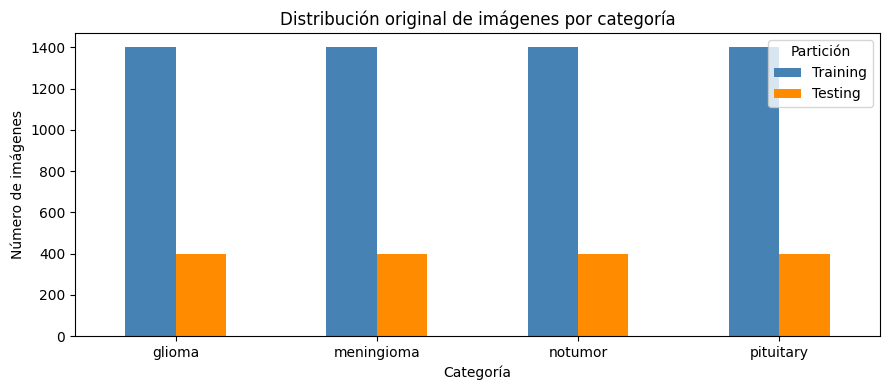

In [6]:
ax = distribution[["Training", "Testing"]].plot(
    kind="bar",
    figsize=(9, 4),
    color=["steelblue", "darkorange"],
    rot=0
)

ax.set_title("Distribución original de imágenes por categoría")
ax.set_xlabel("Categoría")
ax.set_ylabel("Número de imágenes")
ax.legend(title="Partición")

plt.tight_layout()
plt.show()

### 2.4 Inspección visual del entrenamiento

Se muestran tres imágenes de cada categoría del conjunto Training
para observar diferencias de encuadre, orientación, contraste y tamaño.

Esta exploración permite conocer los datos, pero no constituye
una interpretación médica ni verifica la exactitud de las etiquetas.

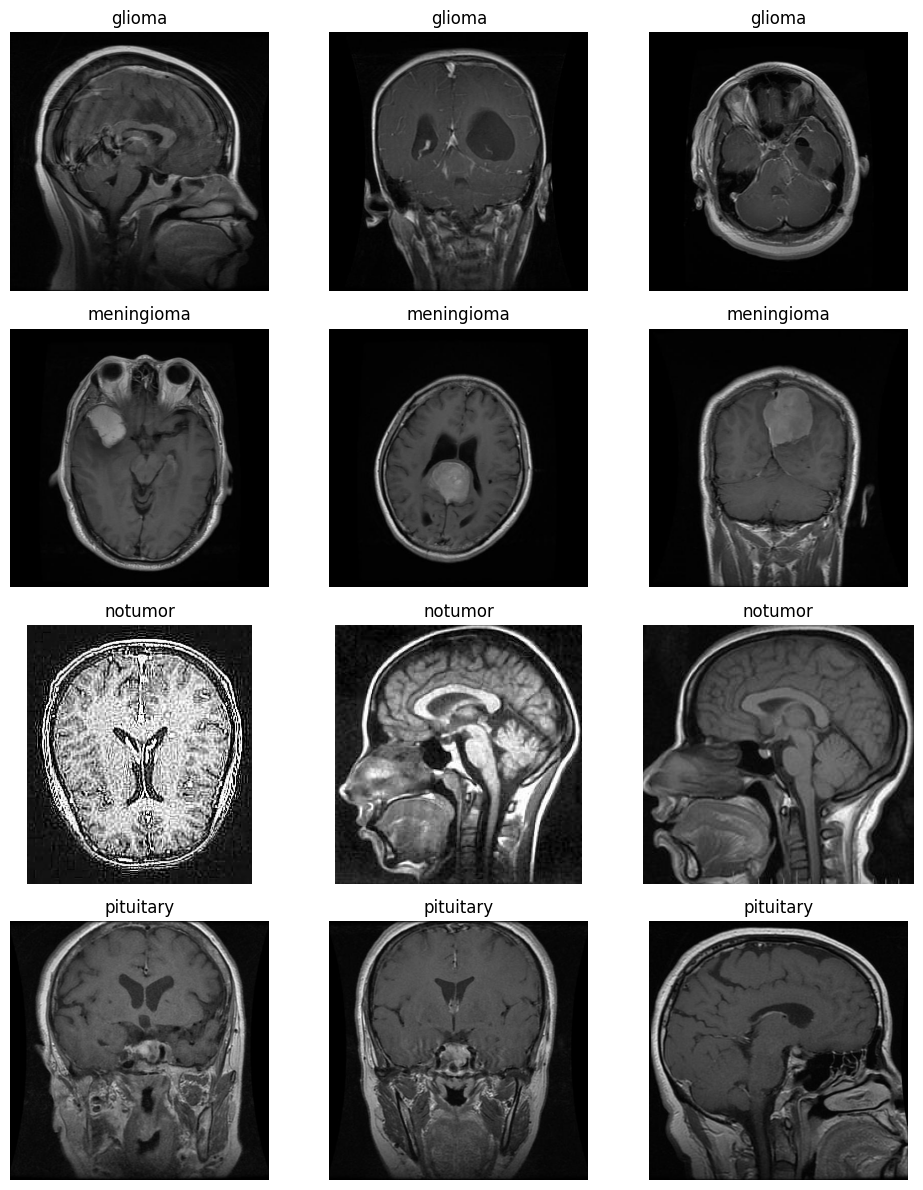

In [7]:
training_original_df = df[
    df["original_split"] == "Training"
].copy()

class_names = sorted(expected_classes)

fig, axes = plt.subplots(4, 3, figsize=(10, 12))

for row_index, class_name in enumerate(class_names):

    examples = training_original_df[
        training_original_df["class_name"] == class_name
    ].sample(
        n=3,
        random_state=SEED
    )

    for ax, image_path in zip(
        axes[row_index],
        examples["path"]
    ):
        with Image.open(image_path) as image:
            ax.imshow(image.convert("RGB"))

        ax.set_title(class_name)
        ax.axis("off")

plt.tight_layout()
plt.show()

#### Observaciones de la inspección visual

La muestra contiene imágenes con distintas orientaciones, encuadres,
contrastes y proporciones de fondo negro.

También se observan diferencias en la apariencia y textura entre imágenes,
particularmente en uno de los ejemplos de la categoría notumor.

Estas variaciones podrían influir en el aprendizaje. El modelo podría
aprovechar características de adquisición o procesamiento asociadas
con las fuentes del dataset, además de los patrones de interés.

La inspección corresponde únicamente a la muestra visualizada y no
permite verificar las etiquetas ni establecer conclusiones clínicas.

### 2.5 Revisión de calidad y duplicados

Se comprueba que cada archivo pueda abrirse y decodificarse.
Se registran sus dimensiones y una huella de sus píxeles RGB para
identificar imágenes exactamente iguales.

Se revisan duplicados dentro de las particiones, coincidencias entre
Training y Testing y grupos con etiquetas diferentes.

Esta revisión no modifica los archivos originales. Los duplicados
aproximados y la posible presencia del mismo paciente en diferentes
conjuntos requieren controles adicionales.

In [8]:
import hashlib

valid_rows = []
invalid_rows = []

for row in df.itertuples(index=False):
    try:
        with Image.open(row.path) as image:
            image = image.convert("RGB")
            image.load()

            # Identificar imágenes con dimensiones y píxeles idénticos
            content = str(image.size).encode() + image.tobytes()
            fingerprint = hashlib.sha256(content).hexdigest()

            valid_rows.append({
                "path": row.path,
                "class_name": row.class_name,
                "original_split": row.original_split,
                "width": image.width,
                "height": image.height,
                "hash": fingerprint
            })

    except Exception as error:
        invalid_rows.append({
            "path": row.path,
            "error": str(error)
        })

checked_df = pd.DataFrame(valid_rows)

assert not checked_df.empty, "No se encontraron imágenes legibles."

print("Imágenes revisadas:", len(df))
print("Imágenes legibles:", len(checked_df))
print("Imágenes con errores:", len(invalid_rows))

display(
    checked_df[["width", "height"]]
    .describe()
    .round(1)
)

# Guardar el registro de errores, aunque esté vacío
pd.DataFrame(
    invalid_rows,
    columns=["path", "error"]
).to_csv(
    OUTPUT_DIR / "archivos_invalidos.csv",
    index=False
)

Imágenes revisadas: 7200
Imágenes legibles: 7200
Imágenes con errores: 0


,width,height
count,7200.0,7200.0
mean,453.3,456.9
std,130.0,124.4
min,150.0,167.0
25%,442.0,449.0
50%,512.0,512.0
75%,512.0,512.0
max,1375.0,1446.0


In [9]:
# Cantidad de archivos con cada huella
hash_counts = checked_df["hash"].value_counts()

print(
    "Grupos de imágenes exactas repetidas:",
    int((hash_counts > 1).sum())
)

print(
    "Copias adicionales respecto a una imagen por huella:",
    len(checked_df) - checked_df["hash"].nunique()
)

# Detectar imágenes idénticas con categorías diferentes
labels_per_hash = (
    checked_df.groupby("hash")["class_name"].nunique()
)

conflict_hashes = labels_per_hash[
    labels_per_hash > 1
].index

conflict_df = checked_df[
    checked_df["hash"].isin(conflict_hashes)
].copy()

print("Grupos con etiquetas contradictorias:", len(conflict_hashes))
print("Archivos en esos grupos:", len(conflict_df))

# Detectar coincidencias entre las particiones originales
training_hashes = set(
    checked_df.loc[
        checked_df["original_split"] == "Training",
        "hash"
    ]
)

testing_hashes = set(
    checked_df.loc[
        checked_df["original_split"] == "Testing",
        "hash"
    ]
)

shared_hashes = training_hashes.intersection(testing_hashes)

print(
    "Imágenes únicas presentes en Training y Testing:",
    len(shared_hashes)
)

conflict_df.to_csv(
    OUTPUT_DIR / "conflictos_etiquetas.csv",
    index=False
)

Grupos de imágenes exactas repetidas: 277
Copias adicionales respecto a una imagen por huella: 322
Grupos con etiquetas contradictorias: 0
Archivos en esos grupos: 0
Imágenes únicas presentes en Training y Testing: 111


#### Resultados de la revisión de calidad

Las 7,200 imágenes pudieron leerse correctamente. Sus dimensiones
promedio fueron de 453.3 píxeles de ancho y 456.9 de alto.

Se identificaron 277 grupos de imágenes exactamente repetidas,
que representan 322 copias adicionales. No se encontraron etiquetas
contradictorias entre las imágenes idénticas.

Se detectaron 111 imágenes únicas presentes tanto en Training como
en Testing. Esta coincidencia puede producir fuga de información
y una evaluación demasiado optimista.

### 2.6 Limpieza de duplicados

Se conservará una sola copia de cada imagen exacta dentro de cada
partición. Cuando exista una coincidencia entre Training y Testing,
se conservará la imagen de Testing y se eliminará su copia de Training.

La limpieza se realizará sobre las tablas de trabajo, sin borrar
ni modificar los archivos originales.

Este procedimiento evita coincidencias exactas entre conjuntos,
pero no garantiza independencia por paciente ni elimina todas
las imágenes visualmente similares.

In [10]:
# Separar las particiones originales
training_raw_df = checked_df[
    checked_df["original_split"] == "Training"
].copy()

testing_raw_df = checked_df[
    checked_df["original_split"] == "Testing"
].copy()

# Conservar una copia de cada imagen dentro de cada partición
training_unique_df = training_raw_df.drop_duplicates(
    subset="hash"
).copy()

test_df = testing_raw_df.drop_duplicates(
    subset="hash"
).copy()

# Quitar de entrenamiento las imágenes presentes en prueba
test_hashes = set(test_df["hash"])

development_df = training_unique_df[
    ~training_unique_df["hash"].isin(test_hashes)
].copy()

development_df = development_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(
    "Copias eliminadas dentro de Training:",
    len(training_raw_df) - len(training_unique_df)
)

print(
    "Copias eliminadas dentro de Testing:",
    len(testing_raw_df) - len(test_df)
)

print(
    "Imágenes retiradas de Training por aparecer en Testing:",
    len(training_unique_df) - len(development_df)
)

print("\nImágenes para entrenamiento y validación:", len(development_df))
print("Imágenes de prueba:", len(test_df))
print("Total después de limpiar:", len(development_df) + len(test_df))

# Verificar que no queden coincidencias exactas
assert development_df["hash"].is_unique
assert test_df["hash"].is_unique

assert set(development_df["hash"]).isdisjoint(
    test_df["hash"]
)

assert set(development_df["class_name"]) == expected_classes
assert set(test_df["class_name"]) == expected_classes

print("\nVerificación correcta: no quedan duplicados exactos compartidos.")

display(
    pd.DataFrame({
        "Desarrollo": development_df["class_name"].value_counts(),
        "Prueba": test_df["class_name"].value_counts()
    }).sort_index()
)

Copias eliminadas dentro de Training: 190
Copias eliminadas dentro de Testing: 21
Imágenes retiradas de Training por aparecer en Testing: 111

Imágenes para entrenamiento y validación: 5299
Imágenes de prueba: 1579
Total después de limpiar: 6878

Verificación correcta: no quedan duplicados exactos compartidos.


,Desarrollo,Prueba
class_name,,
glioma,1396,383
meningioma,1288,396
notumor,1257,400
pituitary,1358,400


In [11]:
metadata_extensions = {
    ".csv", ".tsv", ".json", ".xlsx",
    ".txt", ".mat", ".h5", ".hdf5", ".dcm"
}

metadata_files = sorted(
    path
    for path in DATA_PATH.rglob("*")
    if path.is_file()
    and path.suffix.lower() in metadata_extensions
)

print("Archivos candidatos a contener metadatos:", len(metadata_files))

for path in metadata_files[:30]:
    print(path.relative_to(DATA_PATH))

if not metadata_files:
    print(
        "No se encontraron archivos de metadatos en los formatos revisados."
    )

Archivos candidatos a contener metadatos: 0
No se encontraron archivos de metadatos en los formatos revisados.


### 2.7 Separación en entrenamiento, validación y prueba

Después de eliminar duplicados exactos, quedaron 5,299 imágenes
del conjunto Training original y 1,579 del conjunto Testing.

Se reservará el 20 % de las imágenes de desarrollo para validación.
El 80 % restante se utilizará para entrenar los modelos.
La separación será estratificada para mantener aproximadamente
la proporción de las cuatro categorías.

El conjunto Testing limpio permanecerá reservado para evaluar
exclusivamente la versión final seleccionada.

No se encontraron archivos adicionales de metadatos en los formatos
revisados ni se identificó una correspondencia fiable con pacientes.
Por ello, la separación se realiza por imagen y no garantiza
independencia por paciente.

Los resultados deberán interpretarse como desempeño sobre esta
partición de imágenes, no como una evaluación clínica en pacientes
independientes.

In [12]:
from sklearn.model_selection import train_test_split

# Establecer un orden fijo para las cuatro categorías
class_names = sorted(expected_classes)

class_to_id = {
    name: index
    for index, name in enumerate(class_names)
}

NUM_CLASSES = len(class_names)

# Añadir etiquetas numéricas
development_df = development_df.copy()
test_df = test_df.copy()

development_df["label"] = (
    development_df["class_name"].map(class_to_id)
)

test_df["label"] = test_df["class_name"].map(class_to_id)

# Obtener validación únicamente del entrenamiento original limpio
train_df, val_df = train_test_split(
    development_df,
    test_size=0.20,
    stratify=development_df["label"],
    random_state=SEED
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print("Correspondencia de etiquetas:")
print(class_to_id)

print("\nEntrenamiento:", len(train_df))
print("Validación:", len(val_df))
print("Prueba:", len(test_df))

# Mostrar la distribución final
split_distribution = pd.DataFrame({
    "Entrenamiento": train_df["class_name"].value_counts(),
    "Validación": val_df["class_name"].value_counts(),
    "Prueba": test_df["class_name"].value_counts()
}).sort_index()

display(split_distribution)

Correspondencia de etiquetas:
{'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}

Entrenamiento: 4239
Validación: 1060
Prueba: 1579


,Entrenamiento,Validación,Prueba
class_name,,,
glioma,1117,279,383
meningioma,1030,258,396
notumor,1006,251,400
pituitary,1086,272,400


In [13]:
# Comprobar que ninguna imagen exacta se comparte entre conjuntos
assert set(train_df["hash"]).isdisjoint(val_df["hash"])
assert set(train_df["hash"]).isdisjoint(test_df["hash"])
assert set(val_df["hash"]).isdisjoint(test_df["hash"])

# Comprobar que se conservan las categorías y las imágenes
for subset in [train_df, val_df, test_df]:
    assert set(subset["class_name"]) == expected_classes
    assert subset["hash"].is_unique

assert len(train_df) + len(val_df) == len(development_df)

# Guardar las particiones con rutas relativas
for name, subset in [
    ("entrenamiento", train_df),
    ("validacion", val_df),
    ("prueba", test_df)
]:
    manifest = subset[
        ["path", "class_name", "label", "hash"]
    ].copy()

    manifest["path"] = manifest["path"].apply(
        lambda path: str(Path(path).relative_to(DATA_PATH))
    )

    manifest.to_csv(
        OUTPUT_DIR / f"particion_{name}.csv",
        index=False
    )

print("Verificación correcta: no hay imágenes exactas compartidas.")
print("Particiones guardadas para reproducir los experimentos.")

Verificación correcta: no hay imágenes exactas compartidas.
Particiones guardadas para reproducir los experimentos.


### 2.8 Preparación de imágenes y lotes

Las imágenes se convierten a tres canales y se ajustan a 128 × 128 píxeles, conservando su proporción mediante relleno.

Los píxeles permanecen en el rango de 0 a 255. La normalización se realizará dentro de la red neuronal.

Se crean conjuntos con `tf.data` y lotes de 32 imágenes. Solo el entrenamiento se mezcla aleatoriamente; validación y prueba conservan su orden para relacionar las predicciones con sus etiquetas.

In [14]:
AUTOTUNE = tf.data.AUTOTUNE


def load_image(path, label):
    image_bytes = tf.io.read_file(path)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.cast(image, tf.float32)

    image = tf.image.resize_with_pad(
        image,
        target_height=IMG_SIZE[0],
        target_width=IMG_SIZE[1]
    )

    return image, label


def create_dataset(dataframe, training=False):
    paths = dataframe["path"].astype(str).to_numpy()
    labels = dataframe["label"].to_numpy(dtype=np.int32)

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("Imágenes de entrenamiento:", len(train_df))
print("Imágenes de validación:", len(val_df))
print("Imágenes de prueba:", len(test_df))
print("Conjuntos preparados. Prueba reservada para la evaluación final.")

Imágenes de entrenamiento: 4239
Imágenes de validación: 1060
Imágenes de prueba: 1579
Conjuntos preparados. Prueba reservada para la evaluación final.


In [15]:
image_batch, label_batch = next(iter(train_ds))

print("Forma del lote de imágenes:", image_batch.shape)
print("Forma del lote de etiquetas:", label_batch.shape)
print("Tipo de los píxeles:", image_batch.dtype)
print(
    "Rango de píxeles:",
    float(tf.reduce_min(image_batch)),
    "a",
    float(tf.reduce_max(image_batch))
)

assert tuple(image_batch.shape[1:]) == (*IMG_SIZE, 3)
assert image_batch.dtype == tf.float32
assert bool(tf.reduce_all(tf.math.is_finite(image_batch)))
assert float(tf.reduce_min(image_batch)) >= 0.0
assert float(tf.reduce_max(image_batch)) <= 255.0
assert bool(tf.reduce_all(label_batch >= 0))
assert bool(tf.reduce_all(label_batch < NUM_CLASSES))

print("Verificación correcta.")

Forma del lote de imágenes: (32, 128, 128, 3)
Forma del lote de etiquetas: (32,)
Tipo de los píxeles: <dtype: 'float32'>
Rango de píxeles: 0.0 a 255.0
Verificación correcta.


## 3. Desarrollo del modelo inicial

### 3.1 Arquitectura

Se construye una red neuronal convolucional para clasificar las imágenes en las cuatro categorías del dataset.

La arquitectura incluye:

- Normalización de píxeles al rango de 0 a 1.
- Tres bloques convolucionales con activación ReLU y reducción espacial mediante MaxPooling.
- Una capa densa para combinar las características extraídas.
- Dropout para reducir el sobreajuste.
- Una salida Softmax con cuatro unidades.

Se utilizará entropía cruzada categórica dispersa porque las etiquetas están codificadas como números enteros.

In [16]:
keras.utils.set_random_seed(SEED)

initial_model = keras.Sequential(
    [
        keras.Input(shape=(*IMG_SIZE, 3)),

        layers.Rescaling(1.0 / 255),

        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),

        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),

        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),

        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.4),

        layers.Dense(NUM_CLASSES, activation="softmax")
    ],
    name="cnn_inicial"
)

initial_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

initial_model.summary()

Model: "cnn_inicial"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,288,196 (16.36 MB)

 Trainable params: 4,288,196 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

### 3.2 Entrenamiento

El modelo se entrena durante un máximo de 30 épocas.

Se guarda la versión con menor pérdida de validación. El entrenamiento se detiene si esta pérdida no mejora durante seis épocas consecutivas y se restauran los mejores pesos.

También se reduce la tasa de aprendizaje cuando la pérdida de validación deja de mejorar. El conjunto de prueba permanece reservado para la evaluación final.

In [17]:
initial_model_path = OUTPUT_DIR / "cnn_inicial.keras"

initial_callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=str(initial_model_path),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    ),

    keras.callbacks.CSVLogger(
        str(OUTPUT_DIR / "entrenamiento_inicial.csv")
    ),

    keras.callbacks.TerminateOnNaN()
]

history_initial = initial_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=initial_callbacks
)

# Cargar explícitamente la versión con menor pérdida de validación.
initial_model = keras.models.load_model(initial_model_path)

print("Entrenamiento inicial terminado.")
print("Mejor modelo guardado en:", initial_model_path)

Epoch 1/30
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step - accuracy: 0.6074 - loss: 0.9046
Epoch 1: val_loss improved from None to 0.41301, saving model to resultados_brain/cnn_inicial.keras

Epoch 1: finished saving model to resultados_brain/cnn_inicial.keras
133/133 ━━━━━━━━━━━━━━━━━━━━ 29s 146ms/step - accuracy: 0.7320 - loss: 0.6712 - val_accuracy: 0.8434 - val_loss: 0.4130 - learning_rate: 0.0010
Epoch 2/30
132/133 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.8271 - loss: 0.4526
Epoch 2: val_loss improved from 0.41301 to 0.34103, saving model to resultados_brain/cnn_inicial.keras

Epoch 2: finished saving model to resultados_brain/cnn_inicial.keras
133/133 ━━━━━━━━━━━━━━━━━━━━ 11s 82ms/step - accuracy: 0.8401 - loss: 0.4174 - val_accuracy: 0.8915 - val_loss: 0.3410 - learning_rate: 0.0010
Epoch 3/30
132/133 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.8981 - loss: 0.2993
Epoch 3: val_loss improved from 0.34103 to 0.22505, saving model to resultados_brain/cnn_inicial.keras

Epoc

### 3.3 Evaluación del modelo inicial en validación

Se evalúa la versión con menor pérdida de validación mediante accuracy y F1 macro.

Accuracy representa la proporción de imágenes clasificadas correctamente. F1 macro asigna el mismo peso a cada categoría y permite complementar la evaluación global.

También se muestran las curvas de entrenamiento para analizar la evolución del aprendizaje y detectar posibles señales de sobreajuste. El conjunto de prueba permanece reservado.

In [18]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

y_val = val_df["label"].to_numpy()

initial_val_probabilities = initial_model.predict(val_ds, verbose=0)
initial_val_predictions = np.argmax(initial_val_probabilities, axis=1)

initial_val_accuracy = accuracy_score(y_val, initial_val_predictions)
initial_val_f1 = f1_score(
    y_val,
    initial_val_predictions,
    labels=range(NUM_CLASSES),
    average="macro",
    zero_division=0
)

comparison_df = pd.DataFrame(
    [
        {
            "modelo": "CNN inicial",
            "accuracy_validacion": initial_val_accuracy,
            "f1_macro_validacion": initial_val_f1
        }
    ]
)

display(comparison_df.round(4))

initial_report_df = pd.DataFrame(
    classification_report(
        y_val,
        initial_val_predictions,
        labels=range(NUM_CLASSES),
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )
).T

display(initial_report_df.round(4))

comparison_df.to_csv(
    OUTPUT_DIR / "comparacion_validacion.csv",
    index=False
)

initial_report_df.to_csv(
    OUTPUT_DIR / "reporte_validacion_inicial.csv"
)

,modelo,accuracy_validacion,f1_macro_validacion
0,CNN inicial,0.9566,0.9563


,precision,recall,f1-score,support
glioma,0.9668,0.9391,0.9527,279.0000
meningioma,0.9222,0.9186,0.9204,258.0000
notumor,0.9538,0.9880,0.9706,251.0000
pituitary,0.9816,0.9816,0.9816,272.0000
accuracy,0.9566,0.9566,0.9566,0.9566
macro avg,0.9561,0.9568,0.9563,1060.0000
weighted avg,0.9567,0.9566,0.9565,1060.0000


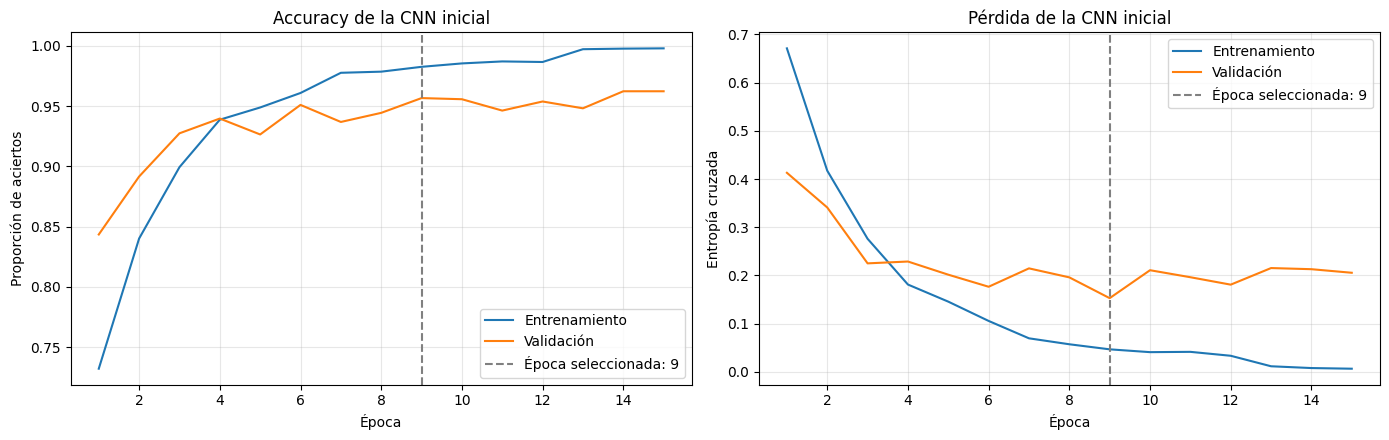

In [19]:
initial_history_df = pd.DataFrame(history_initial.history)
epochs_initial = np.arange(1, len(initial_history_df) + 1)

best_initial_epoch = int(
    np.argmin(initial_history_df["val_loss"]) + 1
)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(
    epochs_initial, initial_history_df["accuracy"],
    label="Entrenamiento"
)
axes[0].plot(
    epochs_initial, initial_history_df["val_accuracy"],
    label="Validación"
)
axes[0].set_title("Accuracy de la CNN inicial")
axes[0].set_ylabel("Proporción de aciertos")

axes[1].plot(
    epochs_initial, initial_history_df["loss"],
    label="Entrenamiento"
)
axes[1].plot(
    epochs_initial, initial_history_df["val_loss"],
    label="Validación"
)
axes[1].set_title("Pérdida de la CNN inicial")
axes[1].set_ylabel("Entropía cruzada")

for ax in axes:
    ax.axvline(
        best_initial_epoch,
        color="gray",
        linestyle="--",
        label=f"Época seleccionada: {best_initial_epoch}"
    )
    ax.set_xlabel("Época")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "curvas_cnn_inicial.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

### 3.4 Análisis del modelo inicial

La CNN inicial obtuvo una accuracy de 95.66 % y un F1 macro de 0.9563 en validación.

La categoría pituitary presentó el mayor F1 (0.9816), mientras que meningioma obtuvo el menor (0.9204).

La menor pérdida de validación se alcanzó en la época 9. Posteriormente, la pérdida de entrenamiento continuó disminuyendo sin una mejora sostenida en validación, lo que muestra señales de sobreajuste.

Estos resultados corresponden a una separación por imágenes. No demuestran generalización a pacientes independientes.

## 4. Ajuste del modelo

### 4.1 Aumento de datos

Se incorpora aumento de datos durante el entrenamiento mediante pequeñas rotaciones, traslaciones y cambios de escala.

El objetivo es reducir la dependencia de la posición y el tamaño exactos de las estructuras en las imágenes. Se utilizan transformaciones suaves, sin inversiones de imagen.

Se mantienen la arquitectura, el optimizador, las particiones y los criterios de entrenamiento del modelo inicial. El nuevo modelo se entrena desde cero y se compara sobre el mismo conjunto de validación.

La mejora se comprobará con los resultados; no se presupone que el aumento de datos produzca un mejor desempeño.

In [20]:
keras.utils.set_random_seed(SEED)

data_augmentation = keras.Sequential(
    [
        layers.RandomRotation(
            factor=0.02,
            fill_mode="constant",
            fill_value=0.0,
            seed=SEED
        ),
        layers.RandomTranslation(
            height_factor=0.04,
            width_factor=0.04,
            fill_mode="constant",
            fill_value=0.0,
            seed=SEED + 1
        ),
        layers.RandomZoom(
            height_factor=(-0.05, 0.05),
            width_factor=(-0.05, 0.05),
            fill_mode="constant",
            fill_value=0.0,
            seed=SEED + 2
        )
    ],
    name="aumento_de_datos"
)

# Copiar la arquitectura sin reutilizar los pesos entrenados.
improved_backbone = keras.models.clone_model(initial_model)

improved_model = keras.Sequential(
    [
        keras.Input(shape=(*IMG_SIZE, 3)),
        data_augmentation,
        improved_backbone
    ],
    name="cnn_aumento_datos"
)

improved_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

improved_model.summary()

Model: "cnn_aumento_datos"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ aumento_de_datos (Sequential)   │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cnn_inicial (Sequential)        │ (None, 4)              │     4,288,196 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,288,196 (16.36 MB)

 Trainable params: 4,288,196 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

In [21]:
improved_model_path = OUTPUT_DIR / "cnn_aumento_datos.keras"

improved_callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=str(improved_model_path),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    ),

    keras.callbacks.CSVLogger(
        str(OUTPUT_DIR / "entrenamiento_aumento_datos.csv")
    ),

    keras.callbacks.TerminateOnNaN()
]

history_improved = improved_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=improved_callbacks
)

improved_model = keras.models.load_model(improved_model_path)

print("Entrenamiento con aumento de datos terminado.")
print("Mejor versión guardada en:", improved_model_path)

Epoch 1/30
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.5504 - loss: 0.9913
Epoch 1: val_loss improved from None to 0.65762, saving model to resultados_brain/cnn_aumento_datos.keras

Epoch 1: finished saving model to resultados_brain/cnn_aumento_datos.keras
133/133 ━━━━━━━━━━━━━━━━━━━━ 25s 84ms/step - accuracy: 0.6520 - loss: 0.8163 - val_accuracy: 0.7528 - val_loss: 0.6576 - learning_rate: 0.0010
Epoch 2/30
132/133 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.7739 - loss: 0.5823
Epoch 2: val_loss improved from 0.65762 to 0.55367, saving model to resultados_brain/cnn_aumento_datos.keras

Epoch 2: finished saving model to resultados_brain/cnn_aumento_datos.keras
133/133 ━━━━━━━━━━━━━━━━━━━━ 10s 76ms/step - accuracy: 0.7865 - loss: 0.5568 - val_accuracy: 0.8019 - val_loss: 0.5537 - learning_rate: 0.0010
Epoch 3/30
132/133 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.8137 - loss: 0.4747
Epoch 3: val_loss improved from 0.55367 to 0.50310, saving model to resultados_brain/c

### 4.2 Comparación en validación

Se evalúa el modelo con aumento de datos utilizando las mismas imágenes y métricas del modelo inicial.

Se seleccionará el modelo con mayor F1 macro de validación. En caso de empate, se utilizará accuracy como criterio secundario.

El conjunto de prueba permanece reservado hasta finalizar la selección.

In [22]:
improved_val_probabilities = improved_model.predict(val_ds, verbose=0)
improved_val_predictions = np.argmax(
    improved_val_probabilities,
    axis=1
)

improved_val_accuracy = accuracy_score(
    y_val,
    improved_val_predictions
)

improved_val_f1 = f1_score(
    y_val,
    improved_val_predictions,
    labels=range(NUM_CLASSES),
    average="macro",
    zero_division=0
)

# Reconstruir la tabla permite ejecutar esta celda sin duplicar filas.
comparison_df = pd.DataFrame(
    [
        {
            "modelo": "CNN inicial",
            "accuracy_validacion": initial_val_accuracy,
            "f1_macro_validacion": initial_val_f1
        },
        {
            "modelo": "CNN con aumento de datos",
            "accuracy_validacion": improved_val_accuracy,
            "f1_macro_validacion": improved_val_f1
        }
    ]
)

display(comparison_df.round(4))

model_candidates = {
    "CNN inicial": initial_model,
    "CNN con aumento de datos": improved_model
}

ranking_df = comparison_df.sort_values(
    ["f1_macro_validacion", "accuracy_validacion"],
    ascending=False,
    kind="stable"
)

selected_model_name = ranking_df.iloc[0]["modelo"]
final_model = model_candidates[selected_model_name]

print("Modelo seleccionado:", selected_model_name)
print(
    "Cambio en accuracy:",
    f"{100 * (improved_val_accuracy - initial_val_accuracy):+.2f}",
    "puntos porcentuales"
)
print(
    "Cambio en F1 macro:",
    f"{improved_val_f1 - initial_val_f1:+.4f}"
)

comparison_df.to_csv(
    OUTPUT_DIR / "comparacion_validacion.csv",
    index=False
)

improved_report_df = pd.DataFrame(
    classification_report(
        y_val,
        improved_val_predictions,
        labels=range(NUM_CLASSES),
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )
).T

display(improved_report_df.round(4))

improved_report_df.to_csv(
    OUTPUT_DIR / "reporte_validacion_aumento_datos.csv"
)

,modelo,accuracy_validacion,f1_macro_validacion
0,CNN inicial,0.9566,0.9563
1,CNN con aumento de datos,0.9632,0.9628


Modelo seleccionado: CNN con aumento de datos
Cambio en accuracy: +0.66 puntos porcentuales
Cambio en F1 macro: +0.0064


,precision,recall,f1-score,support
glioma,0.9573,0.9642,0.9607,279.0000
meningioma,0.9514,0.9109,0.9307,258.0000
notumor,0.9540,0.9920,0.9727,251.0000
pituitary,0.9889,0.9853,0.9871,272.0000
accuracy,0.9632,0.9632,0.9632,0.9632
macro avg,0.9629,0.9631,0.9628,1060.0000
weighted avg,0.9632,0.9632,0.9630,1060.0000


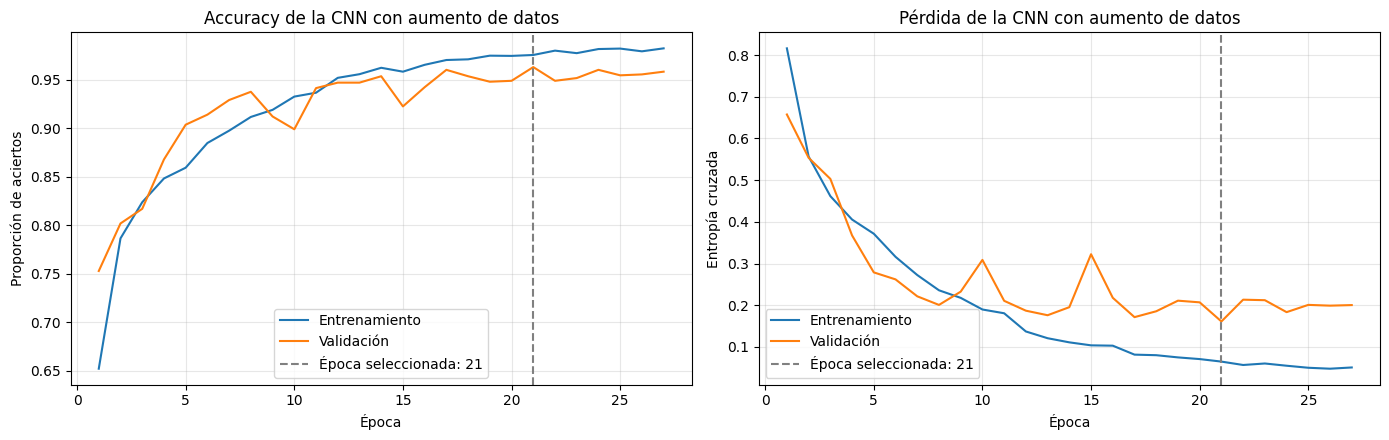

In [23]:
improved_history_df = pd.DataFrame(history_improved.history)
epochs_improved = np.arange(1, len(improved_history_df) + 1)

best_improved_epoch = int(
    np.argmin(improved_history_df["val_loss"]) + 1
)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(
    epochs_improved, improved_history_df["accuracy"],
    label="Entrenamiento"
)
axes[0].plot(
    epochs_improved, improved_history_df["val_accuracy"],
    label="Validación"
)
axes[0].set_title("Accuracy de la CNN con aumento de datos")
axes[0].set_ylabel("Proporción de aciertos")

axes[1].plot(
    epochs_improved, improved_history_df["loss"],
    label="Entrenamiento"
)
axes[1].plot(
    epochs_improved, improved_history_df["val_loss"],
    label="Validación"
)
axes[1].set_title("Pérdida de la CNN con aumento de datos")
axes[1].set_ylabel("Entropía cruzada")

for ax in axes:
    ax.axvline(
        best_improved_epoch,
        color="gray",
        linestyle="--",
        label=f"Época seleccionada: {best_improved_epoch}"
    )
    ax.set_xlabel("Época")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "curvas_cnn_aumento_datos.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

### 4.3 Análisis del ajuste y selección

El modelo con aumento de datos obtuvo una accuracy de 96.32 % y un F1 macro de 0.9628 en validación. Esto representa una mejora de 0.66 puntos porcentuales en accuracy y aproximadamente 0.0064 en F1 macro respecto al modelo inicial.

El F1 de meningioma aumentó de 0.9204 a 0.9307, aunque su recall disminuyó de 0.9186 a 0.9109. Por tanto, la mejora no fue uniforme en todas las métricas.

Las curvas muestran una menor separación de accuracy entre entrenamiento y validación, aunque la medición de entrenamiento incluye imágenes transformadas y Dropout activo. Todavía existe separación entre las pérdidas, por lo que el sobreajuste no desapareció.

El modelo inicial alcanzó una menor pérdida mínima de validación. Sin embargo, se selecciona la CNN con aumento de datos porque obtuvo el mayor F1 macro, criterio establecido para comparar los modelos.

La comparación corresponde a una ejecución de cada configuración; no permite afirmar que la diferencia sea estadísticamente significativa.

### 4.4 Segundo ajuste: transferencia de aprendizaje

Se incorpora MobileNetV2 con pesos preentrenados en ImageNet para evaluar si sus características visuales permiten mejorar la clasificación.

El entrenamiento se realizará en dos etapas:

1. Entrenamiento del clasificador con la base convolucional congelada.
2. Ajuste fino de parte de la base con una tasa de aprendizaje pequeña.

Se conservan las particiones existentes y el aumento de datos suave. Los modelos se compararán mediante F1 macro de validación.

Esta fase es exploratoria porque ya se observaron los resultados del conjunto de prueba. Una evaluación independiente del nuevo proceso requeriría datos adicionales no utilizados durante el desarrollo.

In [28]:
keras.utils.set_random_seed(SEED)

transfer_base = keras.applications.MobileNetV2(
    input_shape=(*IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)
transfer_base.trainable = False

transfer_augmentation = keras.models.clone_model(data_augmentation)

inputs = keras.Input(shape=(*IMG_SIZE, 3))

x = transfer_augmentation(inputs)

# MobileNetV2 requiere píxeles en el rango [-1, 1].
x = layers.Rescaling(1.0 / 127.5, offset=-1)(x)

# Mantener las estadísticas de BatchNormalization.
x = transfer_base(x, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.4)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

transfer_model = keras.Model(
    inputs,
    outputs,
    name="mobilenetv2_brain"
)

transfer_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

transfer_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "mobilenetv2_brain"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aumento_de_datos (Sequential)   │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [29]:
transfer_model_path = OUTPUT_DIR / "mobilenetv2_congelada.keras"

transfer_callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=str(transfer_model_path),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),
    keras.callbacks.CSVLogger(
        str(OUTPUT_DIR / "entrenamiento_mobilenetv2.csv")
    ),
    keras.callbacks.TerminateOnNaN()
]

history_transfer = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=transfer_callbacks
)

# Recuperar los mejores pesos sin reemplazar la referencia a transfer_base.
best_transfer_model = keras.models.load_model(transfer_model_path)
transfer_model.set_weights(best_transfer_model.get_weights())
del best_transfer_model

print("Primera etapa de transferencia terminada.")

Epoch 1/20
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.6862 - loss: 0.8087
Epoch 1: val_loss improved from None to 0.55947, saving model to resultados_brain/mobilenetv2_congelada.keras

Epoch 1: finished saving model to resultados_brain/mobilenetv2_congelada.keras
133/133 ━━━━━━━━━━━━━━━━━━━━ 19s 98ms/step - accuracy: 0.7806 - loss: 0.5775 - val_accuracy: 0.7981 - val_loss: 0.5595 - learning_rate: 0.0010
Epoch 2/20
132/133 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.8611 - loss: 0.3578
Epoch 2: val_loss improved from 0.55947 to 0.36157, saving model to resultados_brain/mobilenetv2_congelada.keras

Epoch 2: finished saving model to resultados_brain/mobilenetv2_congelada.keras
133/133 ━━━━━━━━━━━━━━━━━━━━ 12s 91ms/step - accuracy: 0.8644 - loss: 0.3501 - val_accuracy: 0.8613 - val_loss: 0.3616 - learning_rate: 0.0010
Epoch 3/20
132/133 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.8814 - loss: 0.3157
Epoch 3: val_loss did not improve from 0.36157
133/133 ━━━━━━━━━━━━━━━

### 4.5 Ajuste fino de MobileNetV2

Se descongelan las últimas 30 capas de la base, manteniendo congeladas las capas BatchNormalization.

Se reduce la tasa de aprendizaje a 0.00001 para adaptar las características preentrenadas sin realizar cambios bruscos en los pesos.

Se conserva la versión anterior como referencia. Si el ajuste fino no mejora la pérdida de validación, se recuperan los pesos de la primera etapa.

In [30]:
# Registrar el desempeño antes del ajuste fino.
transfer_val_predictions = np.argmax(
    transfer_model.predict(val_ds, verbose=0),
    axis=1
)

transfer_val_accuracy = accuracy_score(
    y_val, transfer_val_predictions
)
transfer_val_f1 = f1_score(
    y_val,
    transfer_val_predictions,
    labels=range(NUM_CLASSES),
    average="macro",
    zero_division=0
)

transfer_previous_loss = float(
    transfer_model.evaluate(val_ds, verbose=0)[0]
)

print(f"Accuracy antes del ajuste: {transfer_val_accuracy:.4f}")
print(f"F1 macro antes del ajuste: {transfer_val_f1:.4f}")
print(f"Pérdida antes del ajuste: {transfer_previous_loss:.4f}")

# Conservar los pesos para recuperar esta versión si fuera necesario.
transfer_weights_before_fine = [
    weight.copy() for weight in transfer_model.get_weights()
]

transfer_base.trainable = True

for layer in transfer_base.layers[:-30]:
    layer.trainable = False

for layer in transfer_base.layers[-30:]:
    layer.trainable = not isinstance(
        layer, layers.BatchNormalization
    )

# Es necesario recompilar después de modificar las capas entrenables.
transfer_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

print(
    "Capas entrenables de la base:",
    sum(layer.trainable for layer in transfer_base.layers)
)

Accuracy antes del ajuste: 0.8792
F1 macro antes del ajuste: 0.8763
Pérdida antes del ajuste: 0.3402
Capas entrenables de la base: 19


In [31]:
fine_model_path = OUTPUT_DIR / "mobilenetv2_ajuste_fino.keras"

fine_callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=str(fine_model_path),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),
    keras.callbacks.CSVLogger(
        str(OUTPUT_DIR / "entrenamiento_ajuste_fino.csv")
    ),
    keras.callbacks.TerminateOnNaN()
]

history_fine = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    callbacks=fine_callbacks
)

best_fine_loss = float(np.min(history_fine.history["val_loss"]))

if np.isfinite(best_fine_loss) and best_fine_loss < transfer_previous_loss:
    best_fine_model = keras.models.load_model(fine_model_path)
    transfer_model.set_weights(best_fine_model.get_weights())
    del best_fine_model

    transfer_candidate_name = "MobileNetV2 ajuste fino"
    print("El ajuste fino mejoró la pérdida de validación.")
else:
    transfer_model.set_weights(transfer_weights_before_fine)

    transfer_candidate_name = "MobileNetV2 congelada"
    print("Se conserva la versión anterior al ajuste fino.")

print(f"Pérdida anterior: {transfer_previous_loss:.4f}")
print(f"Mejor pérdida del ajuste: {best_fine_loss:.4f}")
print("Versión conservada:", transfer_candidate_name)

Epoch 1/25
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.9088 - loss: 0.2331
Epoch 1: val_loss improved from None to 0.30531, saving model to resultados_brain/mobilenetv2_ajuste_fino.keras

Epoch 1: finished saving model to resultados_brain/mobilenetv2_ajuste_fino.keras
133/133 ━━━━━━━━━━━━━━━━━━━━ 19s 98ms/step - accuracy: 0.9188 - loss: 0.2149 - val_accuracy: 0.8972 - val_loss: 0.3053 - learning_rate: 1.0000e-05
Epoch 2/25
132/133 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.9267 - loss: 0.1894
Epoch 2: val_loss did not improve from 0.30531
133/133 ━━━━━━━━━━━━━━━━━━━━ 11s 84ms/step - accuracy: 0.9316 - loss: 0.1759 - val_accuracy: 0.8698 - val_loss: 0.3805 - learning_rate: 1.0000e-05
Epoch 3/25
132/133 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.9329 - loss: 0.1602
Epoch 3: val_loss improved from 0.30531 to 0.28438, saving model to resultados_brain/mobilenetv2_ajuste_fino.keras

Epoch 3: finished saving model to resultados_brain/mobilenetv2_ajuste_fino.keras
133/133

### 4.6 Comparación de los modelos

Se comparan las dos CNN, MobileNetV2 congelada y su versión posterior al ajuste fino mediante accuracy y F1 macro de validación.

Se selecciona el mayor F1 macro, utilizando accuracy para desempatar. La selección no utiliza las métricas de prueba.

In [32]:
fine_val_predictions = np.argmax(
    transfer_model.predict(val_ds, verbose=0),
    axis=1
)

fine_val_accuracy = accuracy_score(y_val, fine_val_predictions)

fine_val_f1 = f1_score(
    y_val,
    fine_val_predictions,
    labels=range(NUM_CLASSES),
    average="macro",
    zero_division=0
)

comparison_df = pd.DataFrame([
    {
        "modelo": "CNN inicial",
        "accuracy_validacion": initial_val_accuracy,
        "f1_macro_validacion": initial_val_f1
    },
    {
        "modelo": "CNN con aumento de datos",
        "accuracy_validacion": improved_val_accuracy,
        "f1_macro_validacion": improved_val_f1
    },
    {
        "modelo": "MobileNetV2 congelada",
        "accuracy_validacion": transfer_val_accuracy,
        "f1_macro_validacion": transfer_val_f1
    },
    {
        "modelo": transfer_candidate_name,
        "accuracy_validacion": fine_val_accuracy,
        "f1_macro_validacion": fine_val_f1
    }
]).drop_duplicates(subset="modelo", keep="last")

display(comparison_df.round(4))

# Cargar la versión congelada permite seleccionarla si tiene mayor F1.
frozen_transfer_model = keras.models.load_model(transfer_model_path)

model_candidates = {
    "CNN inicial": initial_model,
    "CNN con aumento de datos": improved_model,
    "MobileNetV2 congelada": frozen_transfer_model
}
model_candidates[transfer_candidate_name] = transfer_model

ranking_df = comparison_df.sort_values(
    ["f1_macro_validacion", "accuracy_validacion"],
    ascending=False,
    kind="stable"
)

selected_model_name = ranking_df.iloc[0]["modelo"]
final_model = model_candidates[selected_model_name]

print("Modelo seleccionado:", selected_model_name)

comparison_df.to_csv(
    OUTPUT_DIR / "comparacion_validacion.csv",
    index=False
)

,modelo,accuracy_validacion,f1_macro_validacion
0,CNN inicial,0.9566,0.9563
1,CNN con aumento de datos,0.9632,0.9628
2,MobileNetV2 congelada,0.8792,0.8763
3,MobileNetV2 ajuste fino,0.9387,0.9384


Modelo seleccionado: CNN con aumento de datos


### 4.7 Resultado de la transferencia de aprendizaje

MobileNetV2 congelada obtuvo una accuracy de 87.92 % y un F1 macro de 0.8763 en validación. El ajuste fino aumentó estos valores a 93.87 % y 0.9384, respectivamente.

Aunque el ajuste fino mejoró la transferencia inicial, no superó a la CNN con aumento de datos, que alcanzó 96.32 % de accuracy y 0.9628 de F1 macro.

Por este motivo, se conserva la CNN con aumento de datos como modelo seleccionado. La transferencia de aprendizaje no produjo una mejora respecto a ese modelo en las condiciones evaluadas.

Los errores observados en prueba siguen siendo una limitación del modelo seleccionado. Como trabajo futuro se propone estudiar una mayor resolución de entrada y evaluar con datos externos separados por paciente.

La exploración con MobileNetV2 se realizó después de observar los resultados de prueba. Se documenta esta circunstancia para distinguirla del proceso inicial de selección.

## 5. Evaluación final en prueba

Se evalúa el modelo seleccionado sobre las 1,579 imágenes del conjunto de prueba, que no se utilizaron para entrenar ni seleccionar el modelo.

Se calculan accuracy, F1 macro y métricas por categoría. La matriz de confusión permite identificar los errores entre clases.

Esta evaluación corresponde a imágenes del dataset. La ausencia de identificadores de paciente impide garantizar independencia entre pacientes de las distintas particiones.

In [33]:
y_test = test_df["label"].to_numpy()

test_probabilities = final_model.predict(test_ds, verbose=0)
test_predictions = np.argmax(test_probabilities, axis=1)

assert len(test_predictions) == len(y_test)

test_accuracy = accuracy_score(y_test, test_predictions)
test_f1_macro = f1_score(
    y_test,
    test_predictions,
    labels=range(NUM_CLASSES),
    average="macro",
    zero_division=0
)

print("Modelo final:", selected_model_name)
print(f"Accuracy de prueba: {test_accuracy:.4f}")
print(f"F1 macro de prueba: {test_f1_macro:.4f}")

test_report = classification_report(
    y_test,
    test_predictions,
    labels=range(NUM_CLASSES),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

# Mostrar las categorías y los promedios sin la fila escalar de accuracy.
test_report_df = pd.DataFrame({
    name: values
    for name, values in test_report.items()
    if isinstance(values, dict)
}).T

display(test_report_df.round(4))

test_report_df.to_csv(OUTPUT_DIR / "reporte_prueba.csv")

pd.DataFrame(
    [{
        "modelo": selected_model_name,
        "accuracy_prueba": test_accuracy,
        "f1_macro_prueba": test_f1_macro,
        "imagenes_prueba": len(y_test)
    }]
).to_csv(OUTPUT_DIR / "metricas_prueba.csv", index=False)

test_predictions_df = test_df[
    ["path", "class_name", "label"]
].copy()

test_predictions_df["predicted_label"] = test_predictions
test_predictions_df["predicted_class"] = [
    class_names[index] for index in test_predictions
]
test_predictions_df["correct"] = test_predictions == y_test

test_predictions_df.to_csv(
    OUTPUT_DIR / "predicciones_prueba.csv",
    index=False
)

Modelo final: CNN con aumento de datos
Accuracy de prueba: 0.8556
F1 macro de prueba: 0.8533


,precision,recall,f1-score,support
glioma,0.9467,0.7885,0.8604,383.0
meningioma,0.9312,0.6490,0.7649,396.0
notumor,0.7018,1.0000,0.8247,400.0
pituitary,0.9469,0.9800,0.9631,400.0
macro avg,0.8816,0.8544,0.8533,1579.0
weighted avg,0.8808,0.8556,0.8534,1579.0


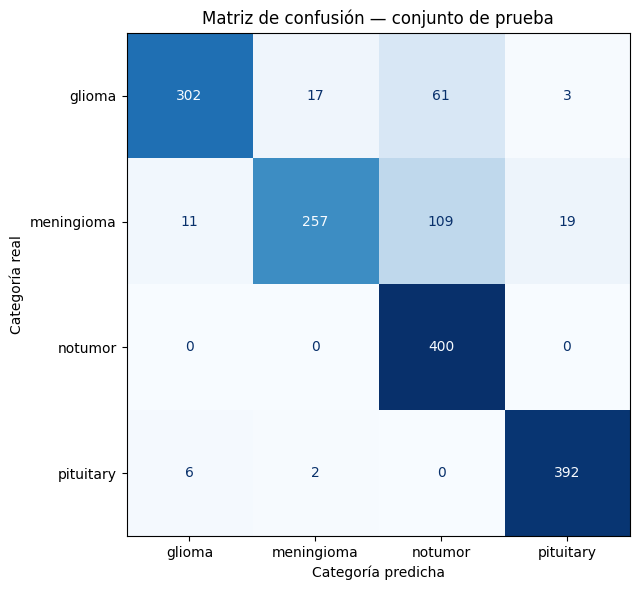

In [34]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

test_cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=range(NUM_CLASSES)
)

fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay(
    confusion_matrix=test_cm,
    display_labels=class_names
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("Matriz de confusión — conjunto de prueba")
ax.set_xlabel("Categoría predicha")
ax.set_ylabel("Categoría real")

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "matriz_confusion_prueba.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

### 5.1 Análisis de los resultados finales

El modelo seleccionado obtuvo una accuracy de 85.56 % y un F1 macro de 0.8533 sobre 1,579 imágenes de prueba. Clasificó correctamente 1,351 imágenes y cometió 228 errores.

La accuracy disminuyó 10.76 puntos porcentuales respecto a validación. Esta diferencia muestra que el desempeño observado en validación no se mantuvo en el conjunto de prueba.

Los principales resultados por categoría fueron:

- **Glioma:** 302 aciertos de 383 imágenes; recall de 78.85 %.
- **Meningioma:** 257 aciertos de 396 imágenes; recall de 64.90 %.
- **Sin tumor:** 400 aciertos de 400 imágenes; recall de 100 %.
- **Pituitary:** 392 aciertos de 400 imágenes; recall de 98 %.

El error más frecuente fue clasificar meningioma como notumor, con 109 casos. También se clasificaron 61 imágenes de glioma como notumor. Esto explica que la precisión de notumor fuera de 70.18 %, a pesar de su recall de 100 %.

La diferencia entre validación y prueba podría relacionarse con variaciones en las imágenes o sus fuentes, pero esta evaluación no permite determinar su causa.

Los resultados corresponden a clasificación de imágenes del dataset y no constituyen una validación clínica ni una evaluación independiente por paciente.

### 5.2 Inspección de aciertos y errores

Se muestran ejemplos seleccionados aleatoriamente de aciertos y errores del conjunto de prueba, utilizando una semilla fija.

Las etiquetas reales corresponden a las proporcionadas por el dataset. Esta inspección permite observar casos concretos, pero no determina por sí sola la causa de los errores.

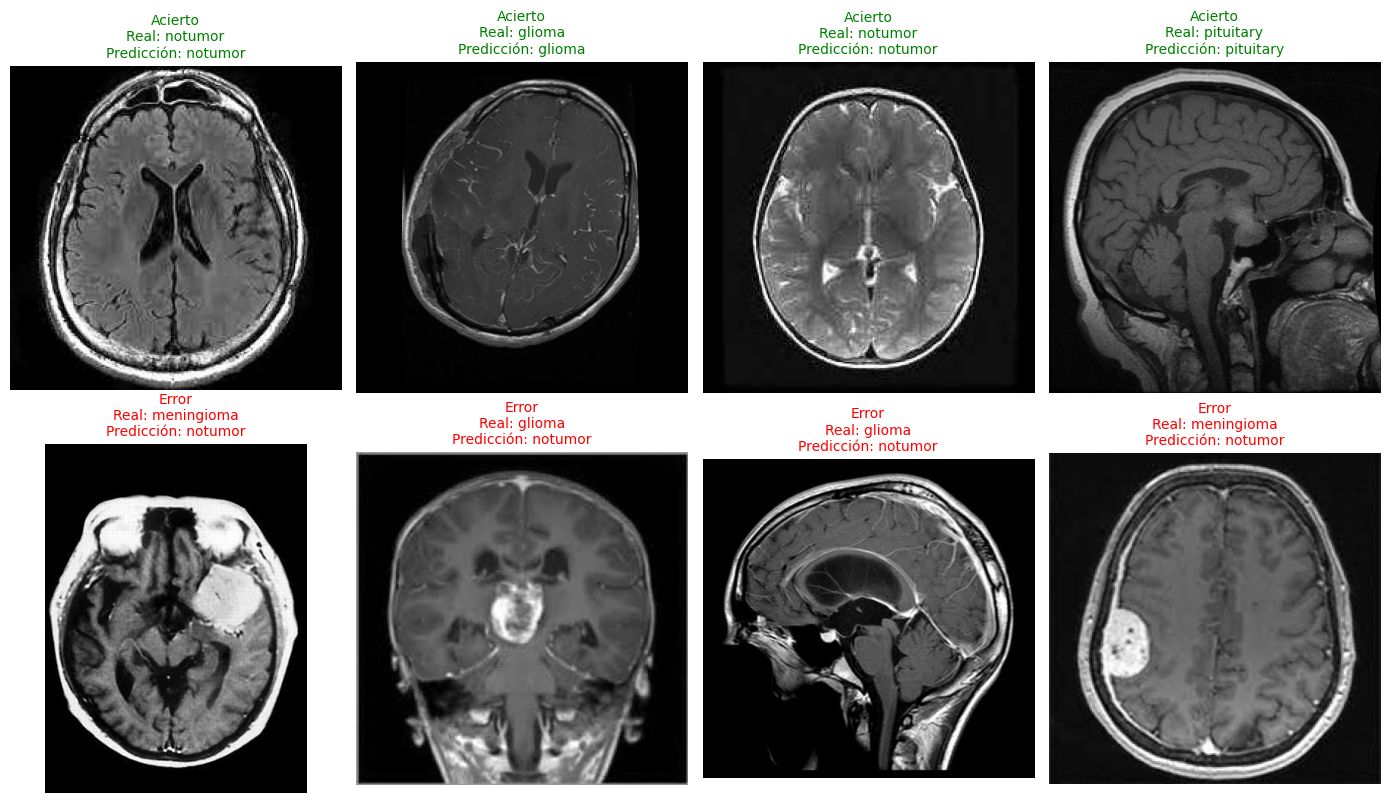

In [35]:
rng = np.random.default_rng(SEED)

correct_indices = np.flatnonzero(test_predictions == y_test)
error_indices = np.flatnonzero(test_predictions != y_test)

fig, axes = plt.subplots(2, 4, figsize=(14, 8))

for row_index, (indices, status, color) in enumerate(
    [
        (correct_indices, "Acierto", "green"),
        (error_indices, "Error", "red")
    ]
):
    selected_indices = rng.choice(
        indices,
        size=min(4, len(indices)),
        replace=False
    )

    for ax in axes[row_index]:
        ax.axis("off")

    for ax, index in zip(axes[row_index], selected_indices):
        record = test_df.iloc[int(index)]

        with Image.open(record["path"]) as image:
            ax.imshow(image.convert("RGB"))

        ax.set_title(
            f"{status}\n"
            f"Real: {class_names[y_test[index]]}\n"
            f"Predicción: {class_names[test_predictions[index]]}",
            color=color,
            fontsize=10
        )

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "ejemplos_prueba.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

### 5.3 Guardado del modelo final

Se guardan la arquitectura y los pesos del modelo seleccionado en formato `.keras`, junto con las etiquetas y la configuración de procesamiento.

Se verifica que el modelo recargado produzca las mismas puntuaciones que el original sobre un lote de validación.

In [36]:
import json

final_model_path = OUTPUT_DIR / "modelo_final.keras"
final_model.save(final_model_path)

with open(OUTPUT_DIR / "etiquetas.json", "w", encoding="utf-8") as file:
    json.dump(class_names, file, ensure_ascii=False, indent=2)

configuration = {
    "modelo_seleccionado": selected_model_name,
    "image_size": list(IMG_SIZE),
    "channels": 3,
    "resize_method": "bilinear",
    "preserve_aspect_ratio": True,
    "padding": "zeros",
    "input_pixel_range": [0, 255],
    "normalization": "Rescaling dentro del modelo",
    "class_names": class_names,
    "seed": SEED,
    "tensorflow_version": tf.__version__,
    "accuracy_prueba": float(test_accuracy),
    "f1_macro_prueba": float(test_f1_macro)
}

with open(
    OUTPUT_DIR / "configuracion.json", "w", encoding="utf-8"
) as file:
    json.dump(configuration, file, ensure_ascii=False, indent=2)

reloaded_model = keras.models.load_model(final_model_path)

verification_images, _ = next(iter(val_ds))

original_scores = final_model(
    verification_images, training=False
).numpy()

reloaded_scores = reloaded_model(
    verification_images, training=False
).numpy()

np.testing.assert_allclose(
    original_scores,
    reloaded_scores,
    rtol=1e-5,
    atol=1e-6
)

print("Modelo final guardado:", final_model_path)
print("Etiquetas y configuración guardadas.")
print("Verificación de recarga correcta.")

Modelo final guardado: resultados_brain/modelo_final.keras
Etiquetas y configuración guardadas.
Verificación de recarga correcta.


## 6. Aplicación: clasificación de imágenes nuevas

Se implementa una función que recibe la ruta de una imagen, aplica el mismo procesamiento utilizado durante el entrenamiento y devuelve las puntuaciones de las cuatro categorías.

La imagen se convierte a RGB y se ajusta a 128 × 128 píxeles conservando su proporción mediante relleno. La normalización está incluida en el modelo.

Las puntuaciones Softmax no representan probabilidades clínicas calibradas. La función es una demostración académica y no permite confirmar ni descartar un tumor.

In [37]:
from PIL import ImageOps

prediction_model = keras.models.load_model(
    OUTPUT_DIR / "modelo_final.keras"
)

with open(
    OUTPUT_DIR / "etiquetas.json", encoding="utf-8"
) as file:
    prediction_classes = json.load(file)

with open(
    OUTPUT_DIR / "configuracion.json", encoding="utf-8"
) as file:
    prediction_config = json.load(file)


def predict_image(image_path, show=True):
    image_path = Path(image_path)

    if not image_path.is_file():
        raise FileNotFoundError(f"No existe el archivo: {image_path}")

    # Pillow también permite abrir formatos como WebP.
    with Image.open(image_path) as image:
        original_image = ImageOps.exif_transpose(image).convert("RGB")
        original_array = np.array(original_image)

    image_tensor = tf.convert_to_tensor(
        original_array,
        dtype=tf.float32
    )

    image_tensor = tf.image.resize_with_pad(
        image_tensor,
        target_height=prediction_config["image_size"][0],
        target_width=prediction_config["image_size"][1],
        method="bilinear"
    )

    scores = prediction_model(
        tf.expand_dims(image_tensor, axis=0),
        training=False
    ).numpy()[0]

    results = pd.DataFrame({
        "categoria": prediction_classes,
        "puntuacion_softmax": scores
    }).sort_values(
        "puntuacion_softmax",
        ascending=False
    ).reset_index(drop=True)

    predicted_class = results.iloc[0]["categoria"]

    if show:
        plt.figure(figsize=(5, 5))
        plt.imshow(original_array)
        plt.title(f"Categoría predicha: {predicted_class}")
        plt.axis("off")
        plt.tight_layout()
        plt.show()

        display(results.round(4))
        print("Demostración académica; no es un diagnóstico.")

    return results


print("Modelo cargado. Función predict_image disponible.")

Modelo cargado. Función predict_image disponible.


### 6.1 Prueba con archivos cargados por el usuario

La siguiente celda permite cargar imágenes desde el equipo y ejecutar la función de predicción.

Esta demostración comprueba el funcionamiento de la aplicación. Las imágenes sin etiquetas verificadas no permiten calcular su desempeño.

Saving notumor.jpg to notumor.jpg
Archivo: notumor.jpg


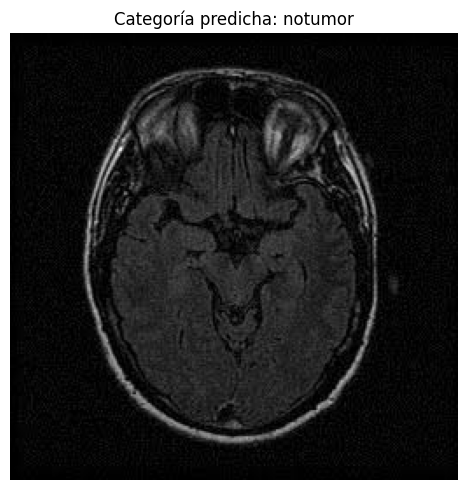

,categoria,puntuacion_softmax
0,notumor,0.9599
1,meningioma,0.0381
2,pituitary,0.0018
3,glioma,0.0001


Demostración académica; no es un diagnóstico.
Predicciones guardadas.


In [39]:
from google.colab import files

uploaded = files.upload()
uploaded_predictions = []

for filename in uploaded:
    print("Archivo:", filename)

    try:
        results = predict_image(filename)

        results.insert(0, "archivo", filename)
        uploaded_predictions.append(results)

    except (OSError, ValueError, tf.errors.OpError) as error:
        print(f"No se pudo procesar {filename}: {error}")

if uploaded_predictions:
    pd.concat(
        uploaded_predictions,
        ignore_index=True
    ).to_csv(
        OUTPUT_DIR / "predicciones_nuevas.csv",
        index=False
    )
    print("Predicciones guardadas.")

### 6.2 Demostración y limitaciones de las predicciones

La imagen utilizada en la demostración corresponde a la categoría notumor. El modelo predijo esa misma categoría con una puntuación Softmax de 0.9599. Este ejemplo comprueba el funcionamiento de la aplicación, pero no sustituye la evaluación sobre el conjunto de prueba.

Una limitación importante es la presencia de falsos negativos: imágenes etiquetadas con tumor que el modelo clasifica como notumor. En prueba ocurrió en 61 imágenes de glioma y 109 de meningioma, para un total de 170 casos.

Estos errores representan el 14.42 % de las 1,179 imágenes etiquetadas con tumor. Por tanto, una predicción notumor no permite descartar su presencia.

Las puntuaciones Softmax no representan certeza clínica.

## 7. Conclusiones

Se desarrolló un clasificador de imágenes de resonancia magnética cerebral con TensorFlow y Keras para cuatro categorías: glioma, meningioma, notumor y pituitary.

Durante la preparación se revisaron 7,200 imágenes y se eliminaron 322 copias adicionales mediante comparación exacta de píxeles. También se eliminaron coincidencias entre entrenamiento y prueba, conservando una imagen por huella. El conjunto resultante incluyó 4,239 imágenes de entrenamiento, 1,060 de validación y 1,579 de prueba.

### Resultados del modelado

La CNN inicial obtuvo un F1 macro de 0.9563 en validación. El aumento de datos elevó este valor a 0.9628 y la accuracy a 96.32 %, por lo que se seleccionó esta configuración.

También se evaluó MobileNetV2. El ajuste fino mejoró su F1 macro de 0.8763 a 0.9384, pero no superó a la CNN con aumento de datos. La transferencia de aprendizaje no produjo una mejora adicional en las condiciones evaluadas.

El modelo seleccionado alcanzó una accuracy de 85.56 % y un F1 macro de 0.8533 en prueba. La diferencia respecto a validación evidencia una limitación de generalización.

### Limitaciones

- Se clasificaron como notumor 170 imágenes etiquetadas con tumor. Estos falsos negativos impiden interpretar una predicción notumor como ausencia de tumor.
- No se encontraron identificadores que permitieran separar los datos por paciente.
- La limpieza detectó duplicados exactos, pero no garantiza la ausencia de imágenes similares o cortes del mismo paciente entre particiones.
- La exploración con MobileNetV2 se realizó después de observar prueba, aunque la selección se mantuvo basada en validación.
- Se realizó una ejecución por configuración; las diferencias no se evaluaron mediante repeticiones o pruebas de significancia.
- La demostración con imágenes individuales no constituye una validación externa.

### Posibles mejoras

Se propone evaluar una mayor resolución de entrada, investigar diferencias entre las fuentes de imágenes y utilizar datos con identificadores de paciente para construir particiones independientes.

También sería conveniente evaluar el modelo en un conjunto externo, analizar la sensibilidad para las categorías con tumor y estudiar la calibración de sus puntuaciones.

### Alcance de la aplicación

Se implementó una función para cargar imágenes, procesarlas y obtener predicciones utilizando el modelo guardado. El sistema cumple una finalidad académica y no está validado para uso clínico.

In [40]:
import shutil
from google.colab import files

archive_path = shutil.make_archive(
    "resultados_brain",
    "zip",
    root_dir=str(OUTPUT_DIR.parent),
    base_dir=OUTPUT_DIR.name
)

files.download(archive_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>